## 3.3 有限元：弱形式与 Galerkin 方法（2 学时）

**本节目标**：从一维 Poisson 方程的弱形式出发，独立装配线性有限元系统，施加 Dirichlet 边界条件；随后用同一制造解比较 FEM 与中心差分 FDM，并复现教材第 15–21 页的误差表、收敛阶与图 3.3-4、图 3.3-5。

> **使用方法：** 从上到下逐格运行，按 `Shift + Enter` 执行代码。每个“检查点”的 `assert` 通过时不会报错；若失败，请停下来检查，不要直接跳到下一步。仅用 NumPy、Matplotlib 完成主要 FEM/FDM 实验；原模板中的 SciPy 差分基线另外保留。

### 1. 从强形式到弱形式（先理解再编程）

$$
-u''(x)=f(x),\quad 0<x<1,\qquad u(0)=u(1)=0.
$$

令 $V=H_0^1(0,1)$，检验函数 $v\in V$。乘以 $v$ 积分并分部积分：

$$
-\int_0^1 u''v\,dx
=\int_0^1 u'v'\,dx-[u'v]_0^1
=\int_0^1 fv\,dx.
$$

因为 **检验函数在端点为零**，边界项才消失。弱形式是：求 $u\in V$，使

$$
\int_0^1 u'v'\,dx=\int_0^1 fv\,dx,\qquad\forall v\in V.
$$

将区间划成 $N$ 个单元，选择满足零边界条件的连续分片线性空间 $V_h\subset V$，并令试探函数与检验函数都属于 $V_h$，便得到 Galerkin 有限元方法。

在单元 $K_e=[x_{e-1},x_e]$，$h_e=x_e-x_{e-1}$ 上，局部形函数为

$$
N_1(x)=\frac{x_e-x}{h_e},\quad
N_2(x)=\frac{x-x_{e-1}}{h_e}.
$$

于是局部刚度矩阵及载荷向量分别为

$$
K^{(e)}=\frac{1}{h_e}
\begin{bmatrix}1&-1\\-1&1\end{bmatrix},\qquad
F^{(e)}=\begin{bmatrix}
\int_{K_e} fN_1\,dx\\[2pt]\int_{K_e} fN_2\,dx
\end{bmatrix}.
$$

刚度矩阵从弱形式积分得到，**不是把差分矩阵直接改名**。

### 2. 实验模型、预测和评价指标

使用制造解

$$
u(x)=\sin(\pi x),\quad u'(x)=\pi\cos(\pi x),
\quad f(x)=\pi^2\sin(\pi x).
$$

已知精确解 **只用于评估误差**；求解器只能调用源项 $f$ 和边界值。选择均匀网格 $N=8,16,32,64,128$，每个网格有 $N+1$ 个节点、$N-1$ 个内部未知量。

- FEM 局部载荷：每个单元 **4 点 Gauss–Legendre** 求积。
- FEM 误差积分：每个单元 **12 点 Gauss–Legendre** 求积。
- FDM：二阶中心差分，在相同节点上求数值解。
- 预期收敛阶：FEM 的 $L^2$ 误差约为 2 阶、$H^1$ 半范数误差约为 1 阶，FDM 的节点最大误差约为 2 阶。
- 代码中不使用随机数；绘图仅展示数值结果，不把图像“看起来接近”当作收敛性证据。

In [26]:
# 第 1 个代码检查点：环境、模型、精确解
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

def u_exact(x):
    return np.sin(np.pi * x)

def du_exact(x):
    return np.pi * np.cos(np.pi * x)

def source(x):
    return np.pi**2 * np.sin(np.pi * x)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print("u(0), u(0.5), u(1):", u_exact(np.array([0.0, 0.5, 1.0])))
assert np.allclose(u_exact(np.array([0.0, 1.0])), [0.0, 0.0], atol=1e-14)
print("检查点 1 通过：模型及边界条件正确")

Python: 3.12.10
NumPy: 1.26.4 Matplotlib: 3.9.2
u(0), u(0.5), u(1): [0.0000000e+00 1.0000000e+00 1.2246468e-16]
检查点 1 通过：模型及边界条件正确


In [41]:
# 第 2 个代码检查点：N=8 的均匀网格
N_demo = 8
x_demo = np.linspace(0.0, 1.0, N_demo + 1)
h_demo = 1.0 / N_demo

print("N =", N_demo, "h =", h_demo)
print("节点坐标 =", x_demo)
print("内部未知数 =", N_demo - 1)
assert len(x_demo) == 9 and np.allclose(np.diff(x_demo), 0.125)
print("检查点 2 通过：8 个单元、9 个节点、7 个内部自由度")

N = 8 h = 0.125
节点坐标 = [0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875 1.   ]
内部未知数 = 7
检查点 2 通过：8 个单元、9 个节点、7 个内部自由度


### 3. 编写单元刚度矩阵和 4 点 Gauss 求积

Gauss–Legendre 的标准点 $\xi_q\in[-1,1]$ 映射到实际单元：

$$
x_q=\frac{x_L+x_R}{2}+\frac{h_e}{2}\xi_q,
\qquad
\int_{x_L}^{x_R}g(x)\,dx
\approx\frac{h_e}{2}\sum_{q=1}^m w_qg(x_q).
$$

下面的 `element_matrices()` 一次返回 $K^{(e)}$ 和 $F^{(e)}$。`n_gauss=4` 对应教材实验，保留参数便于最后改为一点求积。

In [42]:
def element_matrices(x_left, x_right, rhs, n_gauss=4):
    """连续分片线性单元的 2x2 刚度矩阵和 2 维载荷向量。"""
    h_e = x_right - x_left
    if h_e <= 0:
        raise ValueError("单元长度必须为正")

    K_e = np.array([[1.0, -1.0], [-1.0, 1.0]]) / h_e

    xi, w = leggauss(n_gauss)
    xq = (x_left + x_right) / 2 + (h_e / 2) * xi
    N1 = (x_right - xq) / h_e
    N2 = (xq - x_left) / h_e
    fq = rhs(xq)

    F_e = (h_e / 2) * np.array([
        np.sum(w * fq * N1),
        np.sum(w * fq * N2)
    ])
    return K_e, F_e

K_example, F_example = element_matrices(
    0.0, 0.5, lambda x: np.ones_like(x), n_gauss=4
)
print("长度 1/2、f=1 的局部刚度矩阵：\n", K_example)
print("局部载荷向量：", F_example)
assert np.allclose(K_example, [[2, -2], [-2, 2]])
assert np.allclose(F_example, [0.25, 0.25])
print("检查点 3 通过：与手算一致")

长度 1/2、f=1 的局部刚度矩阵：
 [[ 2. -2.]
 [-2.  2.]]
局部载荷向量： [0.25 0.25]
检查点 3 通过：与手算一致


### 4. 逐单元装配整体矩阵

每个单元 $e=1,\ldots,N$ 连接两个全局节点 $(e-1,e)$。将局部矩阵的四个条目、局部载荷的两个条目累加到相应全局位置，先形成包含全部节点的 $K^{\mathrm{all}}$、$F^{\mathrm{all}}$。

**注意：** 这个完整装配矩阵在尚未施加 Dirichlet 条件时是奇异的，不能直接求解 $K^{\mathrm{all}}U=F^{\mathrm{all}}$。

In [43]:
def assemble_fem(x, rhs, n_gauss=4):
    """按单元装配全节点刚度矩阵、载荷向量（尚未施加边界条件）。"""
    n_nodes = len(x)
    K_all = np.zeros((n_nodes, n_nodes))
    F_all = np.zeros(n_nodes)

    for e in range(n_nodes - 1):
        K_e, F_e = element_matrices(x[e], x[e + 1], rhs, n_gauss)
        idx = [e, e + 1]  # 局部节点 -> 全局节点
        K_all[np.ix_(idx, idx)] += K_e
        F_all[idx] += F_e
    return K_all, F_all

x_two = np.array([0.0, 0.5, 1.0])
f_one = lambda x: np.ones_like(x)
K_two, F_two = assemble_fem(x_two, f_one)
print("两单元的完整装配矩阵：\n", K_two)
print("两单元的完整载荷向量：", F_two)

assert np.allclose(K_two, [[2, -2, 0], [-2, 4, -2], [0, -2, 2]])
assert np.allclose(F_two, [0.25, 0.5, 0.25])
print("检查点 4 通过：共享节点的刚度和载荷正确累加")

两单元的完整装配矩阵：
 [[ 2. -2.  0.]
 [-2.  4. -2.]
 [ 0. -2.  2.]]
两单元的完整载荷向量： [0.25 0.5  0.25]
检查点 4 通过：共享节点的刚度和载荷正确累加


### 5. 施加齐次 Dirichlet 边界条件，解 FEM 系统

已知 $U_0=U_N=0$。内部自由度集合为 $I=\{1,\ldots,N-1\}$，取

$$
K^{\mathrm{all}}_{II}U_I
=F^{\mathrm{all}}_I-K^{\mathrm{all}}_{IB}U_B.
$$

在本节 $U_B=0$，右端简化为 $F_I^{\mathrm{all}}$。`solve_fem` 仍保留边界修正项，避免未来改为非零 Dirichlet 值时产生错误。

In [44]:
def solve_fem(N, rhs=source, n_gauss=4, boundary=(0.0, 0.0)):
    """装配 -> 消去 Dirichlet 边界自由度 -> 恢复全部节点值。"""
    x = np.linspace(0.0, 1.0, N + 1)
    K_all, F_all = assemble_fem(x, rhs, n_gauss)

    U = np.zeros(N + 1)
    U[0], U[-1] = boundary

    K_II = K_all[1:-1, 1:-1]
    right = (F_all[1:-1]
             - K_all[1:-1, 0] * U[0]
             - K_all[1:-1, -1] * U[-1])
    U[1:-1] = np.linalg.solve(K_II, right)
    residual = np.max(np.abs(K_II @ U[1:-1] - right))

    return {
        "x": x, "u": U, "K_all": K_all, "F_all": F_all,
        "K_II": K_II, "rhs_I": right, "residual_inf": residual
    }

two = solve_fem(2, rhs=f_one)
print("两单元内部方程：", two["K_II"][0, 0], "* U1 =", two["rhs_I"][0])
print("中间节点 U1 =", two["u"][1], "；理论值 1/8 =", 1/8)
print("内部系统残差 =", two["residual_inf"])

assert np.isclose(two["u"][1], 1/8)
assert np.allclose(two["u"][[0, -1]], 0)
assert np.allclose(two["K_all"], two["K_all"].T)
assert np.linalg.eigvalsh(two["K_II"]).min() > 0
assert two["residual_inf"] < 1e-12
print("检查点 5 通过：矩阵对称、内部正定、边界和残差正确")

两单元内部方程： 4.0 * U1 = 0.4999999999999999
中间节点 U1 = 0.12499999999999997 ；理论值 1/8 = 0.125
内部系统残差 = 0.0
检查点 5 通过：矩阵对称、内部正定、边界和残差正确


### 6. 保留原 Notebook 的 FDM 差分基线

下一个单元**原样保留**了原文件中使用 `scipy.linalg.solve_banded` 的 Poisson 差分示例。它的参数 `n` 表示 **内部节点数**，对应我们现在的单元数 $N=n+1$。它是独立的差分对照实现，**不能当作 FEM 装配**。

先运行该基线，确认它的节点误差接近二阶下降。

In [46]:
import numpy as np
from scipy.linalg import solve_banded

def solve_poisson(n):
    x = np.arange(1, n + 1) / (n + 1)
    h = 1 / (n + 1)
    band = np.zeros((3, n))
    band[0, 1:] = -1 / h**2
    band[1, :] = 2 / h**2
    band[2, :-1] = -1 / h**2
    u = solve_banded((1, 1), band, np.pi**2 * np.sin(np.pi*x))
    return x, u

errors = []
for n in [15, 31, 63]:
    x, u = solve_poisson(n)
    errors.append(np.max(np.abs(u - np.sin(np.pi*x))))
orders = np.log2(np.array(errors[:-1]) / errors[1:])
assert np.all((orders > 1.95) & (orders < 2.05))
assert errors[-1] < 3e-4
print({"errors": errors, "orders": orders})


{'errors': [0.003218964440079519, 0.0008035776793697824, 0.00020082180969560604], 'orders': array([2.00208724, 2.00052153])}


### 7. 用与 FEM 完全相同的网格实现 FDM

二阶中心差分方程为

$$
\frac{-W_{i-1}+2W_i-W_{i+1}}{h^2}=f(x_i),
\quad i=1,\ldots,N-1.
$$

因为两端为已知 Dirichlet 值，FDM 也只求 $N-1$ 个内部节点值。下面直接组装三对角矩阵，和保留下来的 `solve_poisson(n)` 作交叉核对。

In [47]:
def solve_fdm(N, rhs=source, boundary=(0.0, 0.0)):
    """二阶中心差分；N 个区间，N-1 个内部自由度。"""
    h = 1.0 / N
    x = np.linspace(0.0, 1.0, N + 1)
    n = N - 1
    A = (2.0 * np.eye(n)
         - np.eye(n, k=1) - np.eye(n, k=-1)) / h**2
    b = np.asarray(rhs(x[1:-1]), dtype=float).copy()

    W = np.zeros(N + 1)
    W[0], W[-1] = boundary
    b[0] += W[0] / h**2
    b[-1] += W[-1] / h**2
    W[1:-1] = np.linalg.solve(A, b)
    return {"x": x, "u": W, "A": A,
            "residual_inf": np.max(np.abs(A @ W[1:-1] - b))}

# 直接构造的差分矩阵 与 原始 solve_banded 基线核对
x_old, W_old = solve_poisson(15)  # n=15 个内部点 <=> N=16 个单元
fdm_test = solve_fdm(16)
assert np.allclose(x_old, fdm_test["x"][1:-1])
assert np.allclose(W_old, fdm_test["u"][1:-1], atol=1e-12)
assert fdm_test["residual_inf"] < 1e-10
print("检查点 6 通过：FDM 与原始 SciPy 带状矩阵基线吻合")

检查点 6 通过：FDM 与原始 SciPy 带状矩阵基线吻合


### 8. 复现图 3.3-4：精确解、FEM 折线和 FDM 节点

取 $N=8$。**FEM 绘制为连接数值节点的直线段**；**FDM 只绘制离散节点标记**；精确解用密集的 $x$ 采样绘制光滑正弦曲线。

教材特别指出：尽管本模型的 FEM 中间节点非常准确，单元内部的折线仍不等于精确正弦曲线。

In [51]:
%matplotlib inline

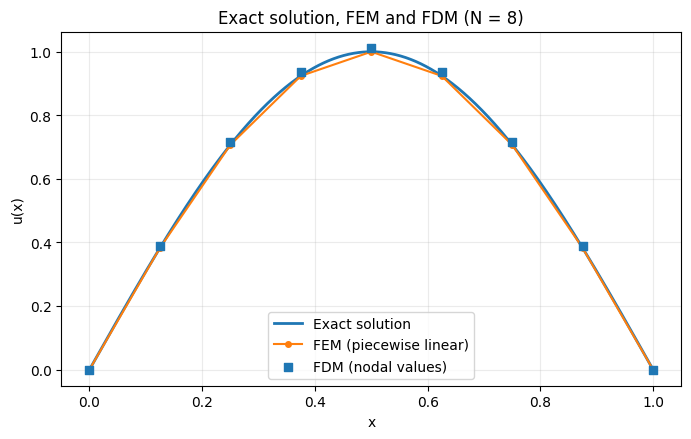

中点 x=0.5：exact=1.000000000, FEM=1.000000000, FDM=1.012950747
检查点 7 通过：图和中点数值符合教材


In [61]:
N_view = 8
fem8 = solve_fem(N_view)
fdm8 = solve_fdm(N_view)
x_fine = np.linspace(0, 1, 1001)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(x_fine, u_exact(x_fine), label="Exact solution", linewidth=2)
ax.plot(fem8["x"], fem8["u"], "-o",
        label="FEM (piecewise linear)", markersize=4)
ax.scatter(fdm8["x"], fdm8["u"], marker="s", s=28,
           label="FDM (nodal values)", zorder=4)
ax.set(xlabel="x", ylabel="u(x)",
       title="Exact solution, FEM and FDM (N = 8)")
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()

print(f"中点 x=0.5：exact={u_exact(0.5):.9f}, "
      f"FEM={fem8['u'][4]:.9f}, FDM={fdm8['u'][4]:.9f}")
assert np.max(np.abs(fem8["u"] - u_exact(fem8["x"]))) < 1e-9
assert np.isclose(fdm8["u"][4], 1.0129507467, atol=1e-9)
print("检查点 7 通过：图和中点数值符合教材")

### 9. 明确定义误差（不要把不同误差混作一个指标）

FEM 节点最大误差：

$$
E_{\infty}^{\mathrm{FEM}}
=\max_{0\le i\le N}|u(x_i)-U_i|.
$$

FDM 节点最大误差：

$$
E_{\infty}^{\mathrm{FDM}}
=\max_{0\le i\le N}|u(x_i)-W_i|.
$$

FEM 在整个区间上的 $L^2$ 误差、$H^1$ **半范数**误差：

$$
E_{L^2}^{\mathrm{FEM}}
=\Big(\sum_e\int_{K_e}(u-u_h)^2\,dx\Big)^{1/2},
\quad
E_{H^1}^{\mathrm{FEM}}
=\Big(\sum_e\int_{K_e}(u'-u'_h)^2\,dx\Big)^{1/2}.
$$

以下函数使用 **12 点 Gauss–Legendre** 求积评价 FEM 积分误差，独立于载荷求积所用的 4 个点。在每个单元上，$u_h$ 是直线，$u_h'$ 是常数。

In [53]:
def fem_integral_errors(x, U, n_gauss=12):
    """在所有单元上积分，返回 (FEM_L2, FEM_H1_seminorm)。"""
    xi, w = leggauss(n_gauss)
    L2_sq = 0.0
    H1_sq = 0.0
    for e in range(len(x) - 1):
        left, right = x[e], x[e + 1]
        h_e = right - left
        xq = (left + right) / 2 + (h_e / 2) * xi

        t = (xq - left) / h_e
        uh_q = (1 - t) * U[e] + t * U[e + 1]
        duh_e = (U[e + 1] - U[e]) / h_e

        L2_sq += (h_e / 2) * np.sum(w * (u_exact(xq) - uh_q)**2)
        H1_sq += (h_e / 2) * np.sum(w * (du_exact(xq) - duh_e)**2)

    return np.sqrt(L2_sq), np.sqrt(H1_sq)

L2_8, H1_8 = fem_integral_errors(fem8["x"], fem8["u"])
print(f"N=8: FEM L2={L2_8:.9f}, FEM H1 seminorm={H1_8:.9f}")
assert np.isclose(L2_8, 0.009920920, atol=1e-9)
assert np.isclose(H1_8, 0.251181769, atol=1e-9)
print("检查点 8 通过：积分误差与教材第 19 页一致")

N=8: FEM L2=0.009920920, FEM H1 seminorm=0.251181769
检查点 8 通过：积分误差与教材第 19 页一致


### 10. 复现表 1：网格加密下的数值误差

依次使用 $N=8,16,32,64,128$，对 **同一个方程** 分别运行 FEM 和 FDM。误差表保留相同的网格定义 $h=1/N$，使用科学记数法打印以便与教材对照。

这里另外打印 FEM 节点误差，但**不要**拿它在接近机器精度时计算收敛阶。

In [54]:
mesh_sizes = [8, 16, 32, 64, 128]
results = []

for N in mesh_sizes:
    fem = solve_fem(N, rhs=source, n_gauss=4)
    fdm = solve_fdm(N, rhs=source)
    E_L2, E_H1 = fem_integral_errors(fem["x"], fem["u"], n_gauss=12)
    E_fem_node = np.max(np.abs(u_exact(fem["x"]) - fem["u"]))
    E_fdm_node = np.max(np.abs(u_exact(fdm["x"]) - fdm["u"]))
    results.append({
        "N": N, "h": 1.0/N, "L2": E_L2, "H1": E_H1,
        "FEM_node": E_fem_node, "FDM_node": E_fdm_node,
        "residual": fem["residual_inf"],
    })

print("表 1：网格加密下的数值误差")
print(f"{'N':>5} {'h':>10} {'FEM L2':>15} {'FEM H1 semi':>15} {'FDM max node':>16}")
for r in results:
    print(f"{r['N']:5d} {r['h']:10.7f} {r['L2']:15.6e} "
          f"{r['H1']:15.6e} {r['FDM_node']:16.6e}")

expected = np.array([
    [9.920920e-3, 2.511818e-1, 1.295075e-2],
    [2.486501e-3, 1.258332e-1, 3.218964e-3],
    [6.220178e-4, 6.294691e-2, 8.035777e-4],
    [1.555290e-4, 3.147724e-2, 2.008218e-4],
    [3.888378e-5, 1.573910e-2, 5.020092e-5]
])
actual = np.array([[r["L2"], r["H1"], r["FDM_node"]] for r in results])
assert np.allclose(actual, expected, rtol=2e-6, atol=1e-9)
assert all(r["residual"] < 1e-9 for r in results)
print("检查点 9 通过：表 1 与教材舍入值吻合，求解残差很小")

表 1：网格加密下的数值误差
    N          h          FEM L2     FEM H1 semi     FDM max node
    8  0.1250000    9.920920e-03    2.511818e-01     1.295075e-02
   16  0.0625000    2.486501e-03    1.258332e-01     3.218964e-03
   32  0.0312500    6.220178e-04    6.294691e-02     8.035777e-04
   64  0.0156250    1.555290e-04    3.147724e-02     2.008218e-04
  128  0.0078125    3.888378e-05    1.573910e-02     5.020092e-05
检查点 9 通过：表 1 与教材舍入值吻合，求解残差很小


### 11. 复现表 2：计算经验收敛阶

若 $E_h\approx Ch^p$，网格步长减半时

$$
p_h=\frac{\log(E_h/E_{h/2})}{\log 2}.
$$

每一行表示从上一层网格加密到当前 $N$ 的收敛阶。理论预期：FEM $L^2\approx2$、FEM $H^1$ 半范数 $\approx1$、FDM 节点最大误差 $\approx2$。

In [55]:
E_L2 = np.array([r["L2"] for r in results])
E_H1 = np.array([r["H1"] for r in results])
E_FDM = np.array([r["FDM_node"] for r in results])
hs = np.array([r["h"] for r in results])

order_L2 = np.log2(E_L2[:-1] / E_L2[1:])
order_H1 = np.log2(E_H1[:-1] / E_H1[1:])
order_FDM = np.log2(E_FDM[:-1] / E_FDM[1:])

print("表 2：网格加密时的经验收敛阶")
print(f"{'fine N':>8} {'FEM L2':>12} {'FEM H1 semi':>15} {'FDM max node':>16}")
for i in range(len(order_L2)):
    print(f"{mesh_sizes[i+1]:8d} {order_L2[i]:12.4f} "
          f"{order_H1[i]:15.4f} {order_FDM[i]:16.4f}")

assert np.all(np.abs(order_L2 - 2.0) < 0.01)
assert np.all(np.abs(order_H1 - 1.0) < 0.01)
assert np.all(np.abs(order_FDM - 2.0) < 0.01)
print("检查点 10 通过：L2 约二阶、H1 半范数约一阶、FDM 节点约二阶")

表 2：网格加密时的经验收敛阶
  fine N       FEM L2     FEM H1 semi     FDM max node
      16       1.9964          0.9972           2.0084
      32       1.9991          0.9993           2.0021
      64       1.9998          0.9998           2.0005
     128       1.9999          1.0000           2.0001
检查点 10 通过：L2 约二阶、H1 半范数约一阶、FDM 节点约二阶


### 12. 复现图 3.3-5：双对数误差收敛曲线

横轴为网格尺寸 $h$，纵轴为误差，均使用对数坐标。**图中从右向左代表 $h$ 减小、网格加密**。在双对数坐标上，斜率大约是经验收敛阶 $p$。

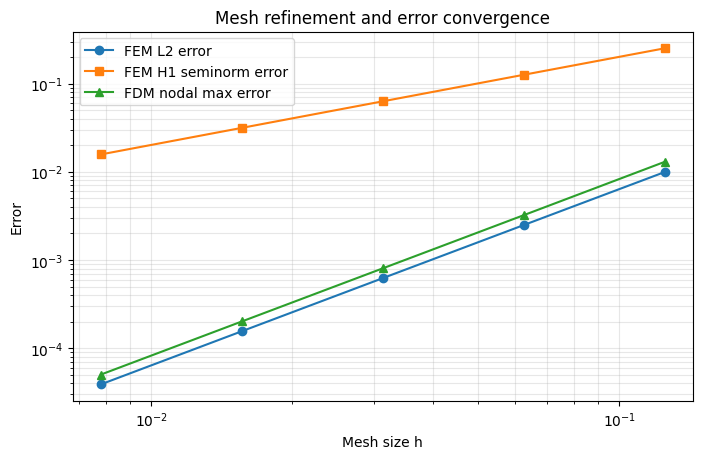

图 3.3-5 已绘制。注意：网格加密方向是从右向左。


In [56]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(hs, E_L2, "-o", label="FEM L2 error")
ax.loglog(hs, E_H1, "-s", label="FEM H1 seminorm error")
ax.loglog(hs, E_FDM, "-^", label="FDM nodal max error")
ax.set(xlabel="Mesh size h", ylabel="Error",
       title="Mesh refinement and error convergence")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()
print("图 3.3-5 已绘制。注意：网格加密方向是从右向左。")

### 13. 为什么 FEM 的节点值几乎完全准确？

对 **本实验的一维常系数 Poisson 问题，且载荷精确积分**，记 $I_hu$ 为精确解的分片线性节点插值函数。由于任意 $v_h\in V_h$ 在每个单元上导数为常数，

$$
\int_{K_e}(u-I_hu)'v_h'\,dx
=v_h'|_{K_e}\left[(u-I_hu)(x_e)-(u-I_hu)(x_{e-1})\right]=0.
$$

求和得到 $a(u-I_hu,v_h)=0$，结合 Galerkin 正交性与离散弱问题的唯一性，推出

$$
\boxed{u_h=I_hu.}
$$

因此在 **理想的精确积分情形**，本模型的 FEM 节点值与精确解节点值一致；4 点 Gauss 不是解析精确积分，但对本题已足够准确，使误差接近舍入精度。**这不是一般 PDE、一般系数或一般有限元的普遍性质。** 同时，$u_h$ 在单元内部依然只是折线，故 $L^2$ 和 $H^1$ 半范数误差不为零。

In [57]:
print("四点 Gauss 积分时 FEM 节点最大误差（仅作精度检查，不拟合阶数）：")
print(f"{'N':>5} {'FEM node max error':>22}")
for r in results:
    print(f"{r['N']:5d} {r['FEM_node']:22.8e}")

assert np.isclose(results[0]["FEM_node"], 2.24e-12, rtol=0.05)
assert np.all(E_L2 > 0) and np.all(E_H1 > 0)
print("检查点 11 通过：节点值接近精确，但单元内部仍存在误差")

四点 Gauss 积分时 FEM 节点最大误差（仅作精度检查，不拟合阶数）：
    N     FEM node max error
    8         2.24220642e-12
   16         8.65973959e-15
   32         3.10862447e-15
   64         9.10382880e-15
  128         8.77076189e-15
检查点 11 通过：节点值接近精确，但单元内部仍存在误差


### 14. 拓展实验：把 FEM 载荷求积改为 1 点

只修改 `n_gauss=1`，保持同一个模型、同一种刚度矩阵、相同误差定义。此时单元载荷积分不再足够精确，FEM 节点最大误差不再接近机器精度；在这个光滑例子上，它会呈现约二阶收敛。

这也回答教材的思考题：**一点 Gauss 下可以计算稳定的节点经验收敛阶，但不能用四点 Gauss 下近机器精度的节点误差计算可靠阶数。**

In [58]:
onepoint_errors = []
for N in mesh_sizes:
    f1 = solve_fem(N, rhs=source, n_gauss=1)
    onepoint_errors.append(
        np.max(np.abs(f1["u"] - u_exact(f1["x"])))
    )
onepoint_errors = np.array(onepoint_errors)
onepoint_orders = np.log2(onepoint_errors[:-1] / onepoint_errors[1:])

print(f"{'N':>5} {'1-point FEM nodal max error':>27} {'order':>10}")
for j, N in enumerate(mesh_sizes):
    p = "—" if j == 0 else f"{onepoint_orders[j-1]:.4f}"
    print(f"{N:5d} {onepoint_errors[j]:27.9e} {p:>10}")

assert np.isclose(onepoint_errors[0], 6.51281784e-3, rtol=1e-6)
assert np.all(np.abs(onepoint_orders - 2) < 0.03)
print("检查点 12 通过：1 点 Gauss 时节点误差约二阶下降")

    N 1-point FEM nodal max error      order
    8             6.512817842e-03          —
   16             1.611809081e-03     2.0146
   32             4.019340600e-04     2.0037
   64             1.004199779e-04     2.0009
  128             2.510102498e-05     2.0002
检查点 12 通过：1 点 Gauss 时节点误差约二阶下降


### 15. 拓展验证：非零 Dirichlet 条件进入哪一步？

取 $-u''=0$、$u(0)=1$、$u(1)=3$，其精确解为 $u(x)=1+2x$。这里内部节点方程的右端应包含 $-K_{IB}U_B$；**不能先当零边界求解，再覆盖两个端点**。

下面用 FEM 和 FDM 的通用求解器验证非零边界。

In [59]:
f_zero = lambda x: np.zeros_like(x)
linear_exact = lambda x: 1 + 2*x

nonzero_fem = solve_fem(8, rhs=f_zero, boundary=(1.0, 3.0))
nonzero_fdm = solve_fdm(8, rhs=f_zero, boundary=(1.0, 3.0))
print("非零边界 FEM 节点：", nonzero_fem["u"])
print("非零边界 FDM 节点：", nonzero_fdm["u"])

assert np.allclose(nonzero_fem["u"], linear_exact(nonzero_fem["x"]))
assert np.allclose(nonzero_fdm["u"], linear_exact(nonzero_fdm["x"]))
print("检查点 13 通过：非零 Dirichlet 边界修正正确")

非零边界 FEM 节点： [1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.  ]
非零边界 FDM 节点： [1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.  ]
检查点 13 通过：非零 Dirichlet 边界修正正确


### 16. 实验结论、易错点与复现记录

**用实际数据验证的结论（运行上述检查点后成立）**

1. 两单元 $f=1$ 的手工装配得到
   $K^{\mathrm{all}}=\begin{bmatrix}2&-2&0\\-2&4&-2\\0&-2&2\end{bmatrix}$，
   $F^{\mathrm{all}}=(1/4,1/2,1/4)^T$，
   $U_1=1/8$。边界节点已知，不参与内部求解。
2. 在 $u=\sin(\pi x)$ 的光滑模型上，FEM 的 $L^2$ 误差约二阶，$H^1$ 半范数误差约一阶；FDM 节点最大误差约二阶。
3. FEM 节点误差的近机器精度表现是**当前问题的特殊性质**，不意味着整个分片线性数值解无误差。
4. FDM 和 FEM 的矩阵形式可能相似，但 FDM 离散强形式、FEM 离散弱形式；**两者的误差指标也不能简单用数值大小直接比较优劣**。

**局限**：这里验证的是一维区间、常系数、均匀网格、光滑制造解和指定积分规则。尚未验证非光滑解、变系数、多维网格、复杂边界或更高阶单元的收敛规律。

**复现设置**：Python + NumPy + Matplotlib；原模板 FDM 基线另用 SciPy；$N=8,16,32,64,128$；FEM 载荷 4 点 Gauss、误差积分 12 点 Gauss；无随机性；图与表由上面的代码运行生成。

In [60]:
# 自动记录运行时间和使用的库版本；不要把编辑时间冒充实验运行时间
from datetime import datetime
import scipy

print("3.3 实际运行记录")
print("运行时间：", datetime.now().astimezone().isoformat(timespec="seconds"))
print("Python：", sys.version.split()[0])
print("NumPy：", np.__version__)
print("Matplotlib：", matplotlib.__version__)
print("SciPy（保留的原始 FDM 基线）：", scipy.__version__)
print("网格：", mesh_sizes)
print("FEM 载荷 Gauss 点数：4；积分误差 Gauss 点数：12")
print("FEM 系统最大残差：", f"{max(r['residual'] for r in results):.3e}")
print("全部 13 个检查点及后续表格、图像均可按顺序复算。")

3.3 实际运行记录
运行时间： 2026-10-20T16:57:16+08:00
Python： 3.12.10
NumPy： 1.26.4
Matplotlib： 3.9.2
SciPy（保留的原始 FDM 基线）： 1.14.1
网格： [8, 16, 32, 64, 128]
FEM 载荷 Gauss 点数：4；积分误差 Gauss 点数：12
FEM 系统最大残差： 4.588e-14
全部 13 个检查点及后续表格、图像均可按顺序复算。


## 3.4 AI关联：Neural ODE与PINN（2学时）

**本节目标：** 能区分学习向量场与基于方程残差的训练目标。

### 概念讲解：把问题说明白

填写提示：Neural ODE的右端模型、数值积分器与PINN残差；本节侧重对应关系和最小ODE例子。

【待填写】用自己的语言讲解，定义符号、适用范围及先修概念；加入一个自己的例子。

### 关键推导：让结论有依据

推导任务：分别写出观测拟合目标和方程残差目标，说明初值、参数与求解器误差的角色。

【待填写】已知条件 → 关键步骤 → 结论 → 条件不满足时的限制。引用定理时写明来源版本和位置。

### 实验设计：先预测，再运行

实验任务：用简单ODE生成轨迹，拟合一个小型右端模型，再以独立步长/求解器评估轨迹；完整PDE PINN在第6章完成。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 待填写 |
| 输入、参数、单位、数据来源与划分 | 待填写 |
| 独立参考解/基线及选择理由 | 待填写 |
| 误差指标、容差及其依据 | 待填写 |
| 环境、种子、设备与运行预算 | 待填写 |

【待填写】在本章Notebook的同号小节编写代码、亲自运行并保存输出。


In [ ]:
# 3.4 输入与独立参考
# TODO：填写本节输入、参数、种子和独立参考；不得用待验证算法自身输出冒充真值。
# 在这里补充代码；完成后删除这条占位提示。
print('3.4 输入与独立参考：未完成，请填写并实际运行。')


In [ ]:
# 3.4 方法实现与运行
# TODO：用简单ODE生成轨迹，拟合一个小型右端模型，再以独立步长/求解器评估轨迹；完整PDE PINN在第6章完成。
# 在这里补充代码；完成后删除这条占位提示。
print('3.4 方法实现与运行：未完成，请填写并实际运行。')


In [ ]:
# 3.4 误差图表与比较
# TODO：给出训练时与评估时的时间网格、轨迹误差和初值范围，说明哪些部分使用了已知方程。
# 在这里补充代码；完成后删除这条占位提示。
print('3.4 误差图表与比较：未完成，请填写并实际运行。')


### 结果解释与本节结论

应提供的证据：给出训练时与评估时的时间网格、轨迹误差和初值范围，说明哪些部分使用了已知方程。

【待填写】实际结果是什么？与预测或理论是否一致？不一致的原因是什么？哪些情况尚未验证？图中注明坐标、单位、图例及参数；未运行则写“未运行”。

### 易错点与讨论

待核验的风险：将求解器产生的误差全归给网络，或将拟合一条轨迹称作已学会所有初值问题。

【待填写】用推导、反例或真实实验回应这条风险。这里是教学讨论提示，不代表已经观察到某个AI的真实错误。

**随堂提问：** 设计改变初值或评估步长后重新验证的题。

【待填写】问题的明确条件、同学可能的回答，以及本组最终解释。


### 3.4 实际运行记录

【待填写】运行日期、完整环境/新增依赖版本、代码状态、输出位置、误差与结论。对照上面的证据要求逐项解释；未运行写未运行。AI辅助内容及人工改动记录在本章模板-A组-AI对话记录.md。

## 回到开场：用证据回答

**本章核心问题：** 如何数值求解ODE和PDE？

【待填写】先回答漫画提出的具体问题，再连接到本章核心问题。保留原预测，指出支持结论的推导、Notebook小节和实际输出，写明比喻的局限。

## 本章小结与课后习题

围绕 **RK4、CFL条件、弱形式** 各写一段：它解决什么问题、适用条件是什么、最容易混淆什么。其他方法说明与这三个概念的联系。

【待填写】本章小结。

课后题按四节对应填写到[模板-A组-习题.md](模板-A组-习题.md)，参考解答单独放在`模板-A组-习题参考解答.md`。

## 选读边界

多步方法、ADI和波动方程移出必修主线；有限元限定为一维线性单元，复杂几何作为选读。

选读不计入本章8学时和最低完成要求。若添加附录，只在此处填写已有材料的名称和链接，不为了占位增加空文档。

## 参考资料、图片来源与AI使用

| 支撑的主张/公式/图片 | 作者、标题、版本/年份 | 页码/章节/链接 | 本组人工核对 |
| --- | --- | --- | --- |
| 待填写 | 待填写 | 待填写 | 未核对 |

漫画为仓库初始化助手绘制的概念示意，A组需结合最终正文核对并记录修改。AI建议与人工结论分开，本章对话分别记录到`模板-A组-AI对话记录.md`、`模板-B组-AI对话记录.md`、`模板-C组-AI对话记录.md`；A/B/C按轮换角色填写。
